## CNN - Lab2 

Found 990 files belonging to 3 classes.


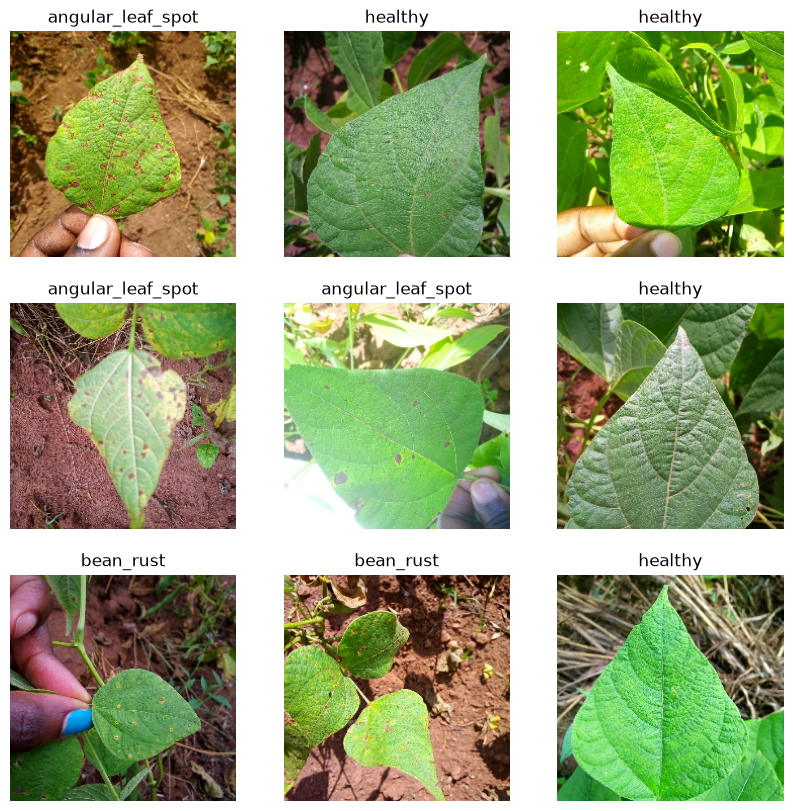

In [1]:
import tensorflow as tf

# Load dataset as a tf.data.Dataset
dataset = tf.keras.utils.image_dataset_from_directory(
    r"E:\Bean_Dataset\Bean_Dataset",
    labels='inferred',
    label_mode='categorical',
    batch_size=32,
    image_size=(224, 224),
    shuffle=True,
    seed=42
)

# Visualize first batch
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 10))
for images, labels in dataset.take(1):
    for i in range(9):
        plt.subplot(3, 3, i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(dataset.class_names[tf.argmax(labels[i])])
        plt.axis('off')
plt.show()

In [15]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
from tensorflow.keras.callbacks import EarlyStopping

In [45]:
X=[]
Y=[]

for images,labels in dataset:
    X.extend(images.numpy())
    Y.extend(labels.numpy())
    
X=np.array(X)
Y=np.array(Y)

print(X.shape)
print(Y.shape)
    

(990, 224, 224, 3)
(990, 3)


In [46]:
xtrain,xtest,ytrain,ytest = train_test_split(
X,Y,
test_size=0.2,
random_state=42
)

print(xtrain[0])
print('--------------')
print(xtrain[0].shape)

[[[ 96.726166  85.413666  57.882336]
  [117.25853   82.6246    69.86567 ]
  [120.96014   78.10866   71.41223 ]
  ...
  [ 63.987804 116.93502   34.068157]
  [ 68.63489  119.786674  32.099155]
  [ 91.06964  139.69011   51.828716]]

 [[110.5668    99.33466   66.37086 ]
  [120.84941   90.5853    72.176025]
  [131.89047   95.5122    83.878265]
  ...
  [ 71.102394 119.16726   40.69406 ]
  [ 80.78857  123.96338   43.204433]
  [122.305725 164.23853   83.53784 ]]

 [[129.58443  121.481346  82.12907 ]
  [138.49673  124.38066   94.59494 ]
  [134.48805  119.53269   93.803024]
  ...
  [ 84.59122  123.84517   43.707294]
  [ 96.5347   133.33022   56.31802 ]
  [122.15026  159.31097   82.15026 ]]

 ...

 [[192.92763  142.92763  180.92763 ]
  [204.62462  154.62462  192.62462 ]
  [218.84755  168.84755  206.84755 ]
  ...
  [143.15773   91.76888  101.16419 ]
  [132.19336   82.19335   93.19335 ]
  [144.00806   95.84734  107.84734 ]]

 [[200.11557  150.11557  188.11557 ]
  [205.52162  153.52162  192.52162 ]


In [47]:
xtrain=xtrain/255.0
xtest=xtest/255.0

In [48]:
num_classes=len(dataset.class_names)
print(Y.shape)

(990, 3)


In [49]:
for i in range(3):
    print(Y[i])

[1. 0. 0.]
[0. 1. 0.]
[0. 1. 0.]


In [50]:
print(X.shape)

(990, 224, 224, 3)


In [51]:
model=Sequential([
    Conv2D(32,(3,3),activation='relu',input_shape=(224,224,3)),
    MaxPooling2D((2,2)),
    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(224,activation='relu'),
    Dropout(0.5),
    Dense(num_classes,activation='softmax')
])

C:\Users\Admin\.conda\envs\DL_Chidvi\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [52]:
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [53]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [54]:
history=model.fit(
    xtrain,
    ytrain,
    epochs=10,
    validation_split=0.2,
    batch_size=32,
    callbacks=[early_stopping]
)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.4013 - loss: 2.4796 - val_accuracy: 0.4088 - val_loss: 1.1161
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 993ms/step - accuracy: 0.5845 - loss: 0.9083 - val_accuracy: 0.6164 - val_loss: 0.7906
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 981ms/step - accuracy: 0.7220 - loss: 0.6927 - val_accuracy: 0.6541 - val_loss: 0.7854
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 963ms/step - accuracy: 0.8278 - loss: 0.5101 - val_accuracy: 0.6352 - val_loss: 0.7695
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 982ms/step - accuracy: 0.8626 - loss: 0.3625 - val_accuracy: 0.6289 - val_loss: 0.8942
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.8799 - loss: 0.3327 - val_accuracy: 0.6101 - val_loss: 1.0213
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 965ms/step - accuracy: 0.9068 - loss: 0.2897 - val_accuracy: 0.7170 - val_loss: 0.7086
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 968ms/step - accuracy: 0.9463 - loss: 0.1633 - val_accuracy: 

In [55]:
test_loss,test_accuracy=model.evaluate(xtest,ytest)
print(f"Test Accuracy :{test_accuracy*100:.2f}%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.7020 - loss: 0.8511
Test Accuracy :70.20%


In [56]:
y_pred = np.argmax(model.predict(xtest), axis=-1)
y_true = np.argmax(ytest, axis=-1)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 105ms/step


In [57]:
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=dataset.class_names))
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))
print("Num of classes",len(dataset.class_names))

Classification Report:
                   precision    recall  f1-score   support

angular_leaf_spot       0.59      0.74      0.66        54
        bean_rust       0.67      0.65      0.66        74
          healthy       0.88      0.73      0.80        70

         accuracy                           0.70       198
        macro avg       0.71      0.71      0.70       198
     weighted avg       0.72      0.70      0.71       198

Confusion Matrix:
[[40 13  1]
 [20 48  6]
 [ 8 11 51]]
Num of classes 3


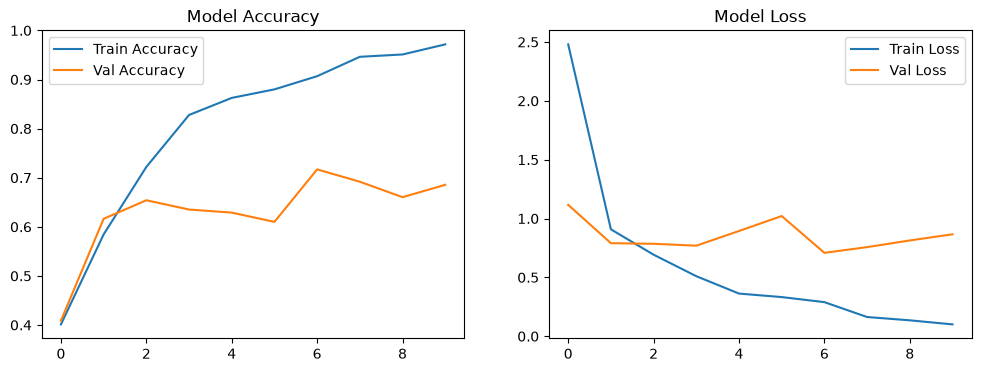

In [58]:
def plot_history(history):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Train Accuracy")
    plt.plot(history.history["val_accuracy"], label="Val Accuracy")
    plt.title("Model Accuracy")
    plt.legend()
    # Plot loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Val Loss")
    plt.title("Model Loss")
    plt.legend()
    plt.show()

plot_history(history)

In [33]:
print(history.history["loss"])
print(history.history["val_loss"])

[721.3551635742188, 0.9762437343597412, 0.7025233507156372, 0.4250869154930115, 0.2346029430627823]
[1.149340033531189, 1.0651739835739136, 1.1376140117645264, 1.2950152158737183, 1.8806853294372559]
